In [28]:
import pandas as pd

# 1. Define the path to where you downloaded the file
file_path = r"D:\adr-detection-project\data\AdverseDrugReaction-master\ADE-Corpus-V2\DRUG-AE.rel"
# 2. Read the .rel file using the pipe delimiter. 
# We set header=None because the original file doesn't have column names.
df = pd.read_csv(file_path, sep='|', header=None)

# 3. Add the proper column names so we know what the data is
df.columns = [
    "PubMed_ID", 
    "Sentence", 
    "Adverse_Effect", 
    "AE_Start", 
    "AE_End", 
    "Drug", 
    "Drug_Start", 
    "Drug_End"
]

# 4. Save it as a standard CSV file in your project folder
df.to_csv(r"D:\adr-detection-project\data\ADE_Corpus_Cleaned.csv", index=False)
print("Conversion successful! Here is what your new CSV looks like:")
print(df.head())

Conversion successful! Here is what your new CSV looks like:
   PubMed_ID                                           Sentence  \
0   10030778      Intravenous azithromycin-induced ototoxicity.   
1   10048291  Immobilization, while Paget's bone disease was...   
2   10048291  Unaccountable severe hypercalcemia in a patien...   
3   10082597  METHODS: We report two cases of pseudoporphyri...   
4   10082597  METHODS: We report two cases of pseudoporphyri...   

              Adverse_Effect  AE_Start  AE_End                Drug  \
0                ototoxicity        43      54        azithromycin   
1  increased calcium-release       960     985  dihydrotachysterol   
2              hypercalcemia        31      44  dihydrotachysterol   
3            pseudoporphyria       620     635            naproxen   
4            pseudoporphyria       620     635           oxaprozin   

   Drug_Start  Drug_End  
0          22        34  
1         908       926  
2          94       112  
3         6

In [29]:
import os
print("Your file is saved in:", os.getcwd())

Your file is saved in: d:\adr-detection-project\data


In [30]:
# 1. Point to the negative text file
neg_file_path = r"D:\adr-detection-project\data\AdverseDrugReaction-master\ADE-Corpus-V2\ADE-NEG.txt"

# 2. Read the negative file. 
# It uses spaces as delimiters, but because sentences have spaces, we only want to split the first two spaces.
# Using 'split' manually is safer here than pd.read_csv for this specific format.
with open(neg_file_path, "r", encoding="utf-8") as file:
    lines = file.readlines()

# Parse the lines: PubMed-ID, the word 'NEG', and the Sentence
neg_data = []
for line in lines:
    parts = line.split(maxsplit=2) # Split only at the first two spaces
    if len(parts) == 3:
        neg_data.append([parts[0], parts[2].strip()]) # Grab ID and Sentence

# Convert to Pandas DataFrame
df_neg = pd.DataFrame(neg_data, columns=["PubMed_ID", "Sentence"])

print(f"Loaded {len(df_neg)} negative sentences.")
print(df_neg.head())

Loaded 16695 negative sentences.
  PubMed_ID                                           Sentence
0   6460590  Clioquinol intoxication occurring in the treat...
1   8600337  "Retinoic acid syndrome" was prevented with sh...
2   8402502  BACKGROUND: External beam radiation therapy of...
3   8700794  Although the enuresis ceased, she developed th...
4  17662448  A 42-year-old woman had uneventful bilateral l...


In [31]:
# 1. Extract just the sentences from your positive DataFrame (which you named 'df' earlier)
df_pos_sentences = df[["Sentence"]].copy()
df_pos_sentences["Label"] = 1 # Positive class

# 2. Extract just the sentences from the negative DataFrame
df_neg_sentences = df_neg[["Sentence"]].copy()
df_neg_sentences["Label"] = 0 # Negative class

# 3. Combine them vertically into one master DataFrame
master_df = pd.concat([df_pos_sentences, df_neg_sentences], ignore_index=True)

# 4. Save the master dataset!
master_df.to_csv("ADE_Master_Dataset.csv", index=False)

print("Master dataset created!")
print(master_df["Label"].value_counts()) # This will show you how balanced the data is

Master dataset created!
Label
0    16695
1     6821
Name: count, dtype: int64


In [32]:

master_df.columns

Index(['Sentence', 'Label'], dtype='object')

In [33]:
neg_count = (master_df['Label'] == 0).sum()
print(neg_count)

16695


In [34]:
pos_count = (master_df['Label'] == 1).sum()
print(pos_count)

6821


--- Basic Health Check ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23516 entries, 0 to 23515
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Sentence  23516 non-null  object
 1   Label     23516 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 367.6+ KB
None

Missing Values:
Sentence    0
Label       0
dtype: int64

--- Class Distribution ---
Label
0    16695
1     6821
Name: count, dtype: int64


C:\Users\Acer\AppData\Local\Temp\ipykernel_4912\2284637484.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Label", palette="Set2")


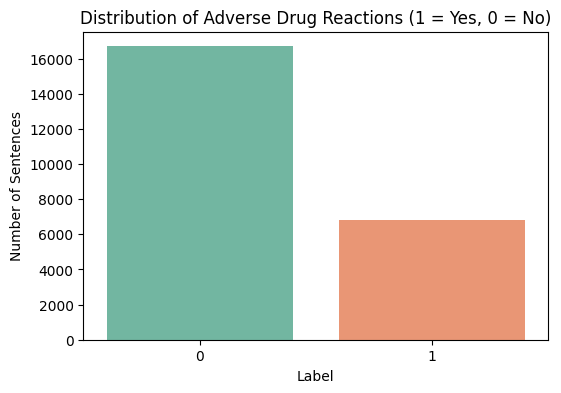

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("ADE_Master_Dataset.csv")
# 2. Basic Data Health Check
print("--- Basic Health Check ---")
print(df.info())
print("\nMissing Values:")
print(df.isnull().sum())

# 3. Class Imbalance Check
print("\n--- Class Distribution ---")
class_counts = df["Label"].value_counts()
print(class_counts)

# Plot the balance
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Label", palette="Set2")
plt.title("Distribution of Adverse Drug Reactions (1 = Yes, 0 = No)")
plt.xlabel("Label")
plt.ylabel("Number of Sentences")
plt.show()


--- Word Count Statistics ---
         count       mean        std  min   25%   50%   75%    max
Label                                                             
0      16695.0  17.711950   8.503848  1.0  12.0  16.0  22.0  135.0
1       6821.0  20.559009  10.049551  2.0  13.0  20.0  27.0   90.0


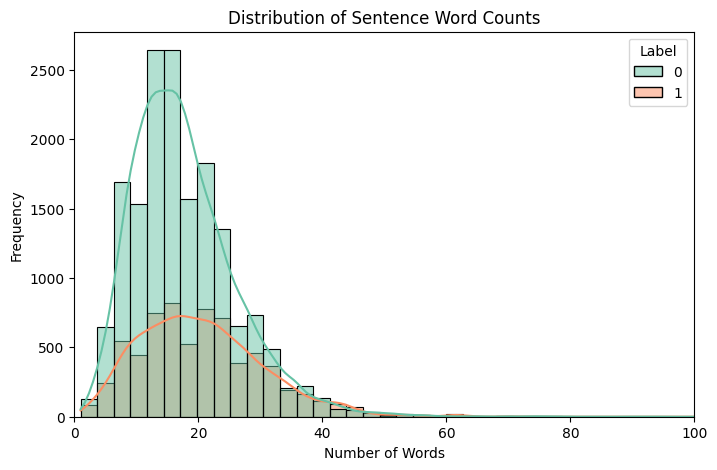

In [39]:
# 4. Sentence Length Analysis (Word Count)
# Create a new column that counts the number of words in each sentence
df['Word_Count'] = df['Sentence'].apply(lambda x: len(str(x).split()))

print("\n--- Word Count Statistics ---")
print(df.groupby('Label')['Word_Count'].describe())

# Plot the word counts to see if ADR sentences are longer than normal ones
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Word_Count", hue="Label", bins=50, kde=True, palette="Set2")
plt.title("Distribution of Sentence Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.xlim(0, 100) # Most sentences won't be longer than 100 words
plt.show()

In [40]:
import re
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Text cleaning function
def clean_medical_text(text):
    text = str(text).lower()
    # Remove citation brackets or internal tags like [1], [2-4]
    text = re.sub(r'\[.*?\]', '', text)
    # Remove non-alphabetical characters (keep basic whitespace)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    # Collapse multiple whitespaces into a single space
    text = re.sub(r'\s+', ' ', text).strip()
    return text

print("Cleaning text...")
df['Cleaned_Sentence'] = df['Sentence'].apply(clean_medical_text)

# 2. Stratified Train-Test Split (80% Train, 20% Test)
X = df['Cleaned_Sentence']
y = df['Label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y  # Ensures both sets have ~29% positive cases
)

print(f"Training samples: {len(X_train)} ({y_train.sum()} positive)")
print(f"Testing samples:  {len(X_test)} ({y_test.sum()} positive)")

# Quick check on a cleaned pair
print("\n--- Sample Comparison ---")
print("Original:", df['Sentence'].iloc[0])
print("Cleaned: ", df['Cleaned_Sentence'].iloc[0])

Cleaning text...
Training samples: 18812 (5457 positive)
Testing samples:  4704 (1364 positive)

--- Sample Comparison ---
Original: Intravenous azithromycin-induced ototoxicity.
Cleaned:  intravenous azithromycin induced ototoxicity


In [41]:
X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)